# 教養娯楽の支出と経済景気との関係性調査

## イントロダクション

本分析では、映画の興行収入・入場者数と経済指標の関係を検証する。

経済学において、景気不況などの経済が厳しい時期に、高額な商品の購入を控える一方で、手頃な価格で購入できる「ささやかな贅沢品」である口紅などの化粧品の売上が伸びる現象が存在している。

上記の現象のエンタメ版として、アメリカにおいては、経済不況時に映画館への客足やチケット売上が伸びる現象が実際に何度も確認されている。この現象は、「バタード・ポップコーン指数（Buttered Popcorn Index）」と呼ばれることもある。

本分析の最初の目的は、日本でも同様な現象が存在しているのかを検証することだったが、分析している中で、映画需要は景気よりも構造的な要因に左右されていることが明らかになった。

本調査で使用している興行収入のデータは、一般社団法人日本映画製作者連盟が発表している過去データ一覧から取得した。(https://www.eiren.org/toukei/data.html)

日本人口に関するデータは第七十五回日本統計年鑑（令和8年）から取得した。(https://www.stat.go.jp/data/nenkan/75nenkan/index.html)

実質GDPに関するデータは内閣府の国民経済計算（GDP統計）から取得した。（https://www.esri.cao.go.jp/jp/sna/data/data_list/sokuhou/files/2026/qe262_2/gdemenuja.html）

消費者態度指数に関するデータはe-Stat 政府統計の総合窓口から取得した。（https://www.e-stat.go.jp/stat-search/files?page=1&layout=datalist&toukei=00100405&tstat=000001014549&cycle=0&tclass1=000001239996&tclass2=000001248808&tclass3val=0）

##　1. 1955以降の日本興行収入及び入場者数の推移

Mounted at /content/drive


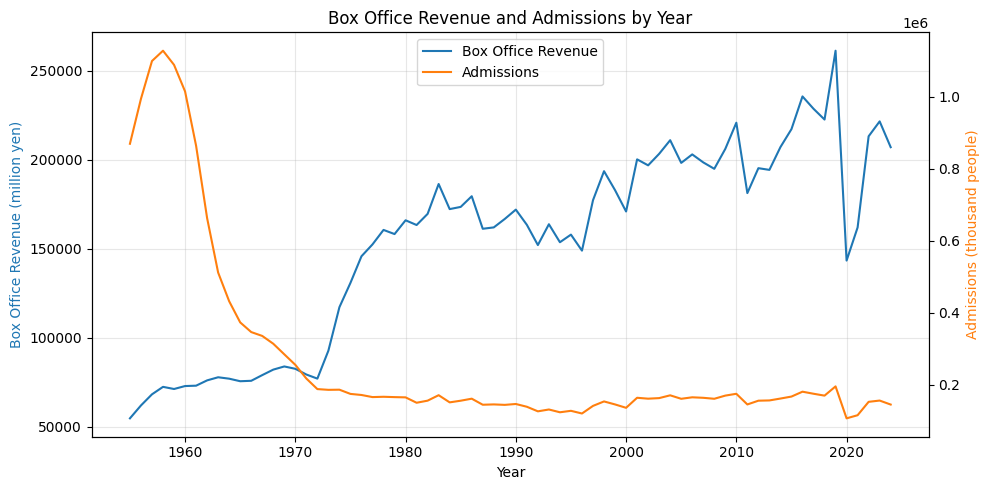

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

# 興行収入関連データを読み込む
boxoffice = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/movie_project/boxoffice_1995-2025.csv", thousands=",")

# 人口データを読み込んでマージ
population = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/movie_project/population.csv",
                         thousands=",", encoding="cp932")
population_total = population[["Total", "year"]].rename(columns={"Total": "population"})

df1 = pd.merge(boxoffice, population_total, on="year")
df1["admissions_per_capita"] = (df1["admissions"] / df1["population"]).round(2)

# グラフを作成
fig, ax1 = plt.subplots(figsize=(10, 5))

# 左軸：興行収入
sns.lineplot(data=df1, x="year", y="box_office_revenue",
             ax=ax1, color="tab:blue", label="Box Office Revenue")
ax1.set_ylabel("Box Office Revenue (million yen)", color="tab:blue")
ax1.set_xlabel("Year")

# 右軸：1人当たり入場回数
ax2 = ax1.twinx()
sns.lineplot(data=df1, x="year", y="admissions",
             ax=ax2, color="tab:orange", label="Admissions")
ax2.set_ylabel("Admissions (thousand people)", color="tab:orange")

# 凡例を追加
ax2.get_legend().remove()
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc="upper center")

plt.title("Box Office Revenue and Admissions by Year")
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()

このグラフにより、1950年代後半から1970年代頭まで、映画館の入場者数が劇的に減少したことがわかる。これは通常の景気変動では説明がつかないほど急激な変化だ。その要因を調べた結果、景気ではなく構造的な変化だった。具体的には、

①テレビの完全な普及及び娯楽の多様化

1960年代にテレビが家庭に急速に普及し、1970年代にはカラーテレビも一般化しました。自宅で無料の映像娯楽を楽しめるようになり、映画は「日常の娯楽」の座をテレビに譲りました。また、1980年代以降、家庭用ビデオとレンタルビデオ店、家庭用ゲーム機などが普及し、映画は「わざわざ映画館で観るもの」ではなくなりました。

②大手映画会社（撮影所システム）の衰退

観客減少による収益悪化で、1971年に大映が倒産し、日活は低予算の成人映画路線へ転換しました。毎週新作を量産する従来のビジネスモデルが崩れ、作品の供給と魅力が低下しました。

③映画館数の減少

採算の合わない映画館が次々と閉館し、身近に映画館がない地域が増えました。アクセスの悪化がさらに客足を遠ざける悪循環が生まれました。

1990年代以降、入場者数はシネマコンプレックス（シネコン）の普及によってスクリーン数が増え、緩やかに回復しましたが、1950年代の水準には戻っていません。入場者数が減少した一方で、平均料金は上昇しているため、興行収入は入場者数ほど落ち込んでいません。業界のビジネスモデルが「低価格・大量動員」から「体験価値への課金」へ移行したことが読み取れます。

##　2. 映画の入場者数と実質GDPの関係

前述の通り、1980年頃まで続いた映画館入場者数の急激な減少は、景気の変動よりも、
テレビの普及や娯楽の多様化といった構造的な要因によるものと考えられる。
この構造変化の影響を除き、景気と映画需要の関係をより純粋に検証するため、
本分析では対象期間を1994年以降（GDP正式系列の開始年）とする。

人口変化の影響を取り除くため、一人当たりの入場回数を用いて、景気（実質GDP）との関係を分析する。


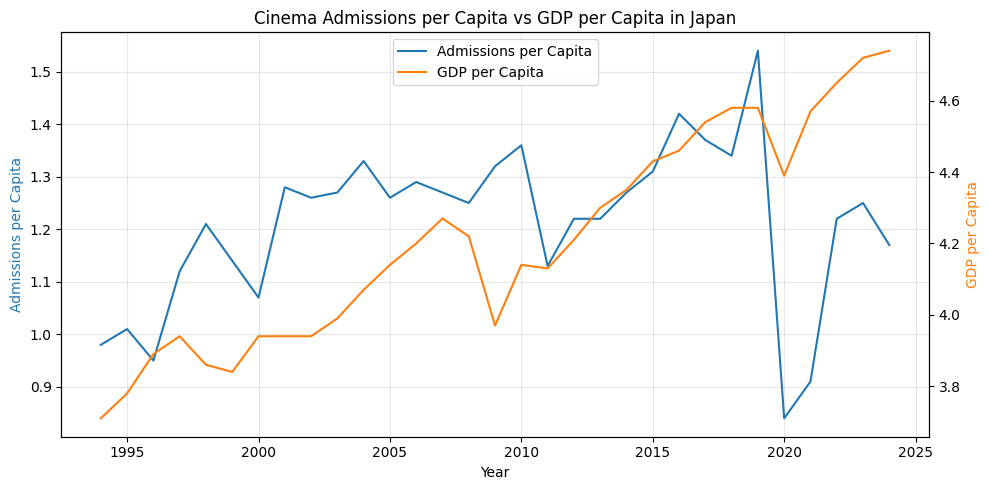

In [23]:
# GDPデータを読み込んでマージ
gdp = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/movie_project/real_gdp_calendar_year_1994~.csv", thousands=",",encoding="cp932")
gdp = gdp[["year","gdp"]]

df2 = pd.merge(df1, gdp, on="year", how = "left")
df2["gdp_per_capita"] = (df2["gdp"] / df2["population"]).round(2)

# グラフを作成
fig, ax1 = plt.subplots(figsize = (10,5))
df_plot1 = df2.dropna(subset =["admissions_per_capita","gdp_per_capita"])

# 左軸：1人当たり入場回数
color1 = "tab:blue"
ax1.plot(df_plot1["year"], df_plot1["admissions_per_capita"], color = color1, label ="Admissions per Capita" )
ax1.set_xlabel("Year")
ax1.set_ylabel("Admissions per Capita", color = color1)

# 右軸：1人あたり名目GDP
ax2 = ax1.twinx()
color2 = "tab:orange"
ax2.plot(df_plot1["year"], df_plot1["gdp_per_capita"], color = color2, label = "GDP per Capita")
ax2.set_ylabel("GDP per Capita", color = color2)

# 凡例を1つにまとめる
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc = "upper center")

plt.title('Cinema Admissions per Capita vs GDP per Capita in Japan')
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()


上のグラフから、1995年から新型コロナウイルスの感染が拡大する2020年まで、日本の一人当たり実質GDPと一人当たり映画館入場回数は、いずれも緩やかな上昇傾向にあったことが分かる。また、コロナ禍の期間には、予想通り両者ともに大きく減少している。一方で、「景気が悪化すると、安価な娯楽である映画の需要がかえって高まる」といった逆方向の動きは、このグラフからは明確に確認できなかった。

次に、単回帰分析を用いて、一人当たり実質GDPと一人当たり映画館入場回数の関係を検証する。

In [14]:
import statsmodels.api as sm

#　一人当たりGDPと映画館入場回数の実際値をベースに回帰分析を実施
df_reg1 = df2.dropna(subset=["gdp_per_capita","admissions_per_capita"])
X = sm.add_constant(df_reg1["gdp_per_capita"])
model1 = sm.OLS(df_reg1["admissions_per_capita"], X).fit()
print(model1.summary())

                              OLS Regression Results                             
Dep. Variable:     admissions_per_capita   R-squared:                       0.091
Model:                               OLS   Adj. R-squared:                  0.060
Method:                    Least Squares   F-statistic:                     2.904
Date:                   Sun, 25 Oct 2026   Prob (F-statistic):             0.0990
Time:                           07:54:59   Log-Likelihood:                 15.964
No. Observations:                     31   AIC:                            -27.93
Df Residuals:                         29   BIC:                            -25.06
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const         

In [32]:
# 極端値であるコロナ禍期間のデータを取り除く
df_nocovid1 = df_reg1[~df_reg1["year"].between(2020, 2022)]
X = sm.add_constant(df_nocovid1["gdp_per_capita"])
model1_1 = sm.OLS(d_nocovid1["admissions_per_capita"], X).fit()
print(model1_1.summary())

                              OLS Regression Results                             
Dep. Variable:     admissions_per_capita   R-squared:                       0.354
Model:                               OLS   Adj. R-squared:                  0.329
Method:                    Least Squares   F-statistic:                     14.23
Date:                   Sun, 25 Oct 2026   Prob (F-statistic):           0.000845
Time:                           13:11:33   Log-Likelihood:                 23.689
No. Observations:                     28   AIC:                            -43.38
Df Residuals:                         26   BIC:                            -40.71
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const         

上記の分析結果から、一人当たり実質GDPの回帰係数は正であり、10%水準で統計的に有意であることが分かる。さらに、コロナ禍期間の極端値を取り除いたら、1%の水準で有意である結果になる。つまり、一人当たり実質GDPが高い年ほど、一人当たり映画館入場回数も多い傾向が見られる。これは、「景気が悪化すると映画の需要が高まる」という本分析の仮説とは反対の結果である。

ただし、決定係数（R²）は低く、一人当たり実質GDPだけでは入場回数の変動の一部しか説明できていない。

さらに、両者はともに右肩上がりで推移しているため、この関係は共通の時間トレンドによる見せかけの相関である可能性がある。両者の真の関係を確認するには、トレンドの影響を取り除いて検証する必要がある。

そこで次に、実数値ではなく前年比の変化率を用いて、改めて回帰分析を行う。

In [38]:
#　一人当たりGDPと映画館入場回数の変化率をベースに回帰分析を実施
df2["gdp_growth"] = df2["gdp_per_capita"].pct_change() * 100
df2["adm_growth"] = df2["admissions_per_capita"].pct_change() * 100
df_reg2 = df2.dropna(subset=["gdp_growth", "adm_growth"])

X = sm.add_constant(df_reg2["gdp_growth"])
model = sm.OLS(df_reg2["adm_growth"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             adm_growth   R-squared:                       0.089
Model:                            OLS   Adj. R-squared:                  0.056
Method:                 Least Squares   F-statistic:                     2.729
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.110
Time:                        13:19:22   Log-Likelihood:                -117.76
No. Observations:                  30   AIC:                             239.5
Df Residuals:                      28   BIC:                             242.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0123      2.501     -0.005      0.9

In [36]:
# 極端値であるコロナ禍期間のデータを取り除く
df_nocovid2 = df_reg2[~df_reg2["year"].between(2020,2022)]
X = sm.add_constant(df_nocovid2["gdp_growth"])
model2_1 = sm.OLS(df_nocovid2["adm_growth"], X).fit()
print(model2_1.summary())

                            OLS Regression Results                            
Dep. Variable:             adm_growth   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                 -0.024
Method:                 Least Squares   F-statistic:                    0.3930
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.536
Time:                        13:16:48   Log-Likelihood:                -93.487
No. Observations:                  27   AIC:                             191.0
Df Residuals:                      25   BIC:                             193.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.2818      1.706      1.337      0.1

上記の分析結果から、一人当たり実質GDPの変化率と一人当たり映画館入場回数の変化率の間には、統計的に有意な関係は確認されなかった。

つまり、トレンドの影響を取り除くと、先ほど見られた正の関係は確認できなくなる。このことから、先ほどの正の関係は両者の実質的な関係ではなく、共通の時間トレンドによる見せかけの相関であった可能性が示唆される。

ただし、GDPが映画需要に影響を与えるとしても、その影響は時間差を伴って現れる可能性も考えられる。そこで次に、前年の一人当たり実質GDPと、当年の映画館入場回数の関係を検証する。

In [39]:
# 1年前の一人当たりGDP変化率の列を作る（年順に並べてから）
df2 = df2.sort_values("year").copy()
df2["gdp_growth_lag1"] = df2["gdp_growth"].shift(1)
df_reg3 = df2.dropna(subset=["gdp_growth_lag1", "adm_growth"])

# 1年前のGDPと映画館入場回数変化率で回帰分析
X = sm.add_constant(df_reg3["gdp_growth_lag1"])
model2 = sm.OLS(df_reg3["adm_growth"], X).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:             adm_growth   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                 -0.017
Method:                 Least Squares   F-statistic:                    0.5282
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.474
Time:                        13:19:30   Log-Likelihood:                -115.38
No. Observations:                  29   AIC:                             234.8
Df Residuals:                      27   BIC:                             237.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.7541      2.687     

In [42]:
df_nocovid3 = df_reg3[~df_reg3["year"].between(2020, 2022)]
X = sm.add_constant(df_nocovid3["gdp_growth_lag1"])
model3_1 = sm.OLS(df_nocovid3["adm_growth"], X).fit()
print(model3_1.summary())

                            OLS Regression Results                            
Dep. Variable:             adm_growth   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.042
Method:                 Least Squares   F-statistic:                 0.0005298
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.982
Time:                        13:21:23   Log-Likelihood:                -90.705
No. Observations:                  26   AIC:                             185.4
Df Residuals:                      24   BIC:                             187.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               1.7974      1.814     

前年の一人当たり実質GDPの変化率を用いた場合も、映画館の一人当たり入場回数との間に統計的に有意な関係は確認されなかった。

以上の結果から、1990年代以降の日本において、景気の変動は映画館の入場回数の変動をほとんど説明しないと考えられる。
映画需要は景気よりも、話題作の公開や、コロナ禍のような外的ショックといった、
映画産業に固有の要因によって左右されている可能性がある。これらの要因の検証は今後の課題とする。

##　3. 映画館の入場者数と消費者態度指数の関係

Text(0.5, 1.0, 'Cinema Admissions per Capita vs Consumer Confidence Index')

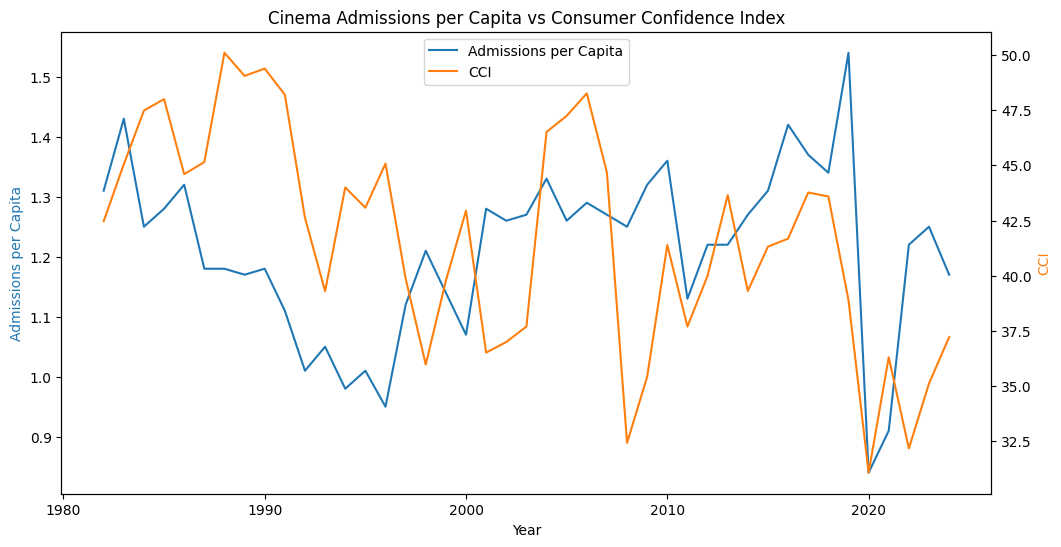

In [24]:
cci = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/movie_project/CCI_1982~2026.csv", thousands=",", encoding = "cp932")
cci.groupby('Year')["CCI"].count()
cci_anual = cci.groupby("Year")["CCI"].mean().round(2).reset_index().rename(columns={"Year":"year"})

df3 = df2.merge(cci_anual, on = "year", how = "left")
# cci_anual ではなく、マージされた列名である "CCI" を指定します
df_plot2 = df3.dropna(subset = ["CCI","admissions_per_capita"])

fig, ax1 = plt.subplots(figsize = (12,6))

ax1.plot(df_plot2["year"], df_plot2["admissions_per_capita"], color = color1, label ="Admissions per Capita" )
ax1.set_xlabel("Year")
ax1.set_ylabel("Admissions per Capita", color = color1)

ax2 = ax1.twinx()
ax2.plot(df_plot2["year"], df_plot2["CCI"], color = color2, label="CCI")
ax2.set_xlabel("year")
ax2.set_ylabel("CCI", color = color2)

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc="upper center")
plt.title("Cinema Admissions per Capita vs Consumer Confidence Index")

注記：2003年以前の消費者態度指数データについて、四半期データのみ、また欠損値が存在する年がある。そのため、近似値として既存データの平均値を使用する。

In [22]:
#　消費者態度指数と映画館入場回数の実際値をベースに回帰分析を実施
X = sm.add_constant(df_plot2["CCI"])
model1 = sm.OLS(df_plot2["admissions_per_capita"], X).fit()
print(model1.summary())

                              OLS Regression Results                             
Dep. Variable:     admissions_per_capita   R-squared:                       0.015
Model:                               OLS   Adj. R-squared:                 -0.009
Method:                    Least Squares   F-statistic:                    0.6288
Date:                   Sun, 25 Oct 2026   Prob (F-statistic):              0.432
Time:                           08:09:59   Log-Likelihood:                 23.173
No. Observations:                     43   AIC:                            -42.35
Df Residuals:                         41   BIC:                            -38.82
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0619 

上記の分析結果を見ると、消費者態度指数と一人当たり入場回数の間にも有意な相関関係が検出されていなかった。

消費者の景況感を最も直接的に反映する消費者態度指数においても有意な関係が見られなかったことは、景気と映画需要の間に関係がないという結論を補強している。

## 示唆

本分析では、エンタメ版のリップスティック効果——不景気に映画のような娯楽支出が増える——を検証したが、日本の映画需要においてその効果は確認できなかった。
さらに、実測値で見られた『GDPと入場回数の正の相関』も、変化率で検証すると消失した。これは共通の時間トレンドによる見かけの相関であり、景気と映画需要の間に安定した関係(正・負いずれも)は見出せなかった。心理面を最も反映するはずの消費者態度指数でも、同様に有意な関係は検出されなかった。

本分析が示したのは、映画需要が景気変動では説明しにくいということである。映画需要は、長期的にはテレビやネット配信の普及という構造的要因に、短期的には話題作の有無やコロナ禍のような外的ショックに左右されている。

### 本分析の限界と今後

・分析対象は映画館の入場に限られ、Netflix等のサブスクによる自宅での映画鑑賞は含まない。不景気に『外出を控え自宅で映画を観る』という代替行動は検証できていない。
・分析期間(1994–2020)における景気後退局面は限られ(主に2008年・2020年)、リップスティック効果を統計的に検証するにはサンプルが少ない。
・今後は、配信サービスの利用データや、他の娯楽(ゲーム・音楽)支出を含めることで、より包括的な検証が可能となる。